# 2do Parcial práctico, Simulación Computacional
Santiago Barrera Meza, código 160005004. Sistema G/G/1, FIFO, T = 60 min.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.float_format', '{:.4f}'.format)

## A. Modelo e implementación
La estructura de sucesos es el diccionario TSuc. Tiene dos entradas: tLL, con el momento de la próxima llegada, y tS, con el de la próxima salida. Cuando alguna no está programada se deja en M.

Las variables de estado son el reloj t y n, el número de clientes en el sistema. Las contadoras son NLL y NS, que llevan la cuenta de llegadas y salidas.

Como variables de salida guardo, para cada cliente, su llegada (LL), su salida (S) y lo que duró su servicio (Serv), además de at y an para graficar n(t). De ahí salen W, Wq, Tp, el máximo de n y el total de clientes.

El reloj no avanza minuto a minuto: salta directo al suceso más cercano en TSuc y ejecuta Llegada o Servidor. Cuando ya no queda nada programado, la simulación termina.

In [2]:
M = 1e12

def simular(T, escenario, semilla):
    rng = np.random.default_rng(semilla)

    def GenerarX():
        return rng.exponential(4.0)

    def GenerarY():
        if escenario == 1:
            return rng.exponential(2.5)
        return max(0.0, rng.normal(3.0, 1.2))

    t = 0.0
    n = NLL = NS = 0
    TSuc = {'tLL': M, 'tS': M}
    LL, S, Serv = [], [], []
    at, an = [0.0], [0]

    def Llegada(tsuc):
        nonlocal t, n, NLL
        t = tsuc
        n += 1
        NLL += 1
        LL.append(t)
        at.append(t)
        an.append(n)
        X = GenerarX()
        if t + X < T:
            TSuc['tLL'] = t + X
        if n == 1:
            Y = GenerarY()
            TSuc['tS'] = t + Y
            Serv.append(Y)

    def Servidor(tsuc):
        nonlocal t, n, NS
        t = tsuc
        n -= 1
        NS += 1
        S.append(t)
        at.append(t)
        an.append(n)
        if n > 0:
            Y = GenerarY()
            TSuc['tS'] = t + Y
            Serv.append(Y)

    X = GenerarX()
    if X < T:
        TSuc['tLL'] = X

    while TSuc['tLL'] != M or TSuc['tS'] != M:
        if TSuc['tLL'] <= TSuc['tS']:
            tsuc = TSuc['tLL']
            TSuc['tLL'] = M
            Llegada(tsuc)
        else:
            tsuc = TSuc['tS']
            TSuc['tS'] = M
            Servidor(tsuc)

    LL, S, Serv = np.array(LL), np.array(S), np.array(Serv)
    W = S - LL
    Wq = W - Serv
    return {
        'W': W,
        'at': np.array(at),
        'an': np.array(an),
        'Tiempo medio en el sistema': W.mean() if NLL else 0.0,
        'Tiempo medio en la cola': Wq.mean() if NLL else 0.0,
        'Tp (T hasta salida del último)': max(0.0, t - T),
        'Máx. clientes en el sistema': int(max(an)),
        'Total de clientes': NLL,
    }

MEDIDAS = ['Tiempo medio en el sistema', 'Tiempo medio en la cola',
           'Tp (T hasta salida del último)', 'Máx. clientes en el sistema', 'Total de clientes']

## B. Escenarios y medidas de desempeño
Una ejecución de cada escenario con T = 60 min.

In [3]:
T = 60.0
SEMILLA = 2026
r1 = simular(T, 1, SEMILLA)
r2 = simular(T, 2, SEMILLA)

tabla_B = pd.DataFrame({'Escenario 1': [r1[m] for m in MEDIDAS],
                        'Escenario 2': [r2[m] for m in MEDIDAS]}, index=MEDIDAS)
tabla_B

,Escenario 1,Escenario 2
Tiempo medio en el sistema,3.2080,5.0375
Tiempo medio en la cola,0.8568,1.9787
Tp (T hasta salida del último),0.0000,0.0000
Máx. clientes en el sistema,3.0000,4.0000
Total de clientes,15.0000,17.0000


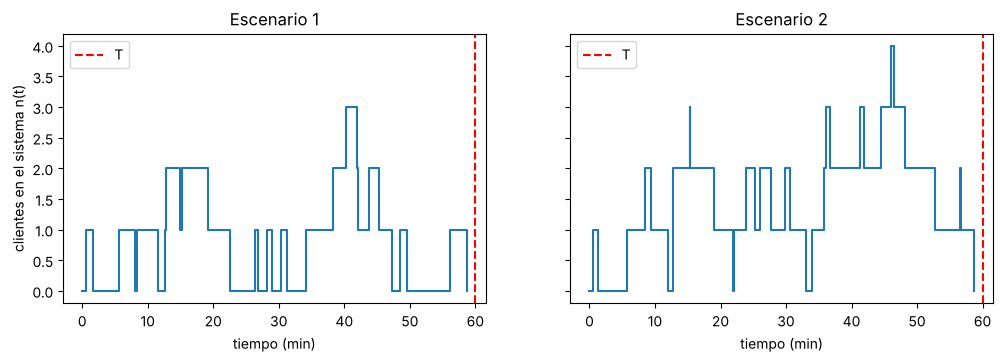

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for a, r, k in zip(ax, (r1, r2), (1, 2)):
    a.step(r['at'], r['an'], where='post')
    a.axvline(T, color='r', ls='--', label='T')
    a.set_title(f'Escenario {k}')
    a.set_xlabel('tiempo (min)')
    a.legend()
ax[0].set_ylabel('clientes en el sistema n(t)')
plt.show()

## C. Réplicas e inferencia
30 réplicas por escenario (semillas 1 a 30) e IC del 95 % con t de Student.

In [5]:
R = 30
semillas = range(1, R + 1)
rep = {k: pd.DataFrame([{m: simular(T, k, s)[m] for m in MEDIDAS} for s in semillas]) for k in (1, 2)}

tcrit = stats.t.ppf(0.975, R - 1)
filas = []
for m in MEDIDAS:
    fila = {'Medida': m}
    for k in (1, 2):
        x = rep[k][m]
        media, de = x.mean(), x.std(ddof=1)
        h = tcrit * de / np.sqrt(R)
        fila[f'E{k} media'] = media
        fila[f'E{k} desv.'] = de
        fila[f'E{k} IC95%'] = f'[{media - h:.3f}, {media + h:.3f}]'
    fila['p-valor (Welch)'] = stats.ttest_ind(rep[1][m], rep[2][m], equal_var=False).pvalue
    filas.append(fila)

tabla_C = pd.DataFrame(filas).set_index('Medida')
tabla_C

,E1 media,E1 desv.,E1 IC95%,E2 media,E2 desv.,E2 IC95%,p-valor (Welch)
Medida,,,,,,,
Tiempo medio en el sistema,5.7751,3.7585,"[4.372, 7.179]",6.0369,2.3422,"[5.162, 6.912]",0.7474
Tiempo medio en la cola,3.3039,3.3052,"[2.070, 4.538]",3.0894,2.3060,"[2.228, 3.950]",0.7718
Tp (T hasta salida del último),3.9495,6.8514,"[1.391, 6.508]",3.8980,5.1268,"[1.984, 5.812]",0.9738
Máx. clientes en el sistema,4.6000,1.8118,"[3.923, 5.277]",4.3000,1.6640,"[3.679, 4.921]",0.5068
Total de clientes,15.9000,4.3814,"[14.264, 17.536]",15.5000,3.6175,"[14.149, 16.851]",0.7013


**Conclusión:** entre los dos escenarios no hay diferencias estadísticamente apreciables. Los intervalos se traslapan en todas las medidas y ningún p-valor de Welch baja de 0.5. Tiene sentido, porque las llegadas son las mismas y el total de clientes casi no cambia. En el escenario 2 el servicio es más lento en promedio (3.0 contra 2.5 min), pero varía mucho menos que el exponencial, y una cosa compensa la otra. A eso se suma que 60 minutos es poco: el sistema empieza vacío, no alcanza a estabilizarse y los resultados cambian bastante de una réplica a otra.

## D. Análisis de los datos
Tiempo en el sistema de cada cliente, Escenario 2 con T = 2000 min.

In [6]:
largo = simular(2000.0, 2, SEMILLA)
x = largo['W']

desc = pd.Series({
    'n': len(x),
    'mínimo': x.min(),
    'máximo': x.max(),
    'media': x.mean(),
    'varianza': x.var(ddof=1),
    'desviación estándar': x.std(ddof=1),
    'Q1 (25 %)': np.percentile(x, 25),
    'Q2 (50 %)': np.percentile(x, 50),
    'Q3 (75 %)': np.percentile(x, 75),
}, name='W (min)')
desc.to_frame()

,W (min)
n,445.0000
mínimo,0.1454
máximo,26.8299
media,6.5499
varianza,18.4283
desviación estándar,4.2928
Q1 (25 %),3.4478
Q2 (50 %),5.2557
Q3 (75 %),8.4353


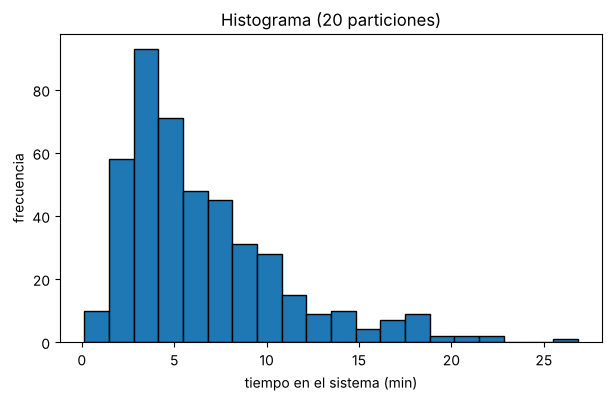

In [7]:
plt.figure(figsize=(7, 4))
frec, bordes, _ = plt.hist(x, bins=20, edgecolor='k')
plt.xlabel('tiempo en el sistema (min)')
plt.ylabel('frecuencia')
plt.title('Histograma (20 particiones)')
plt.show()

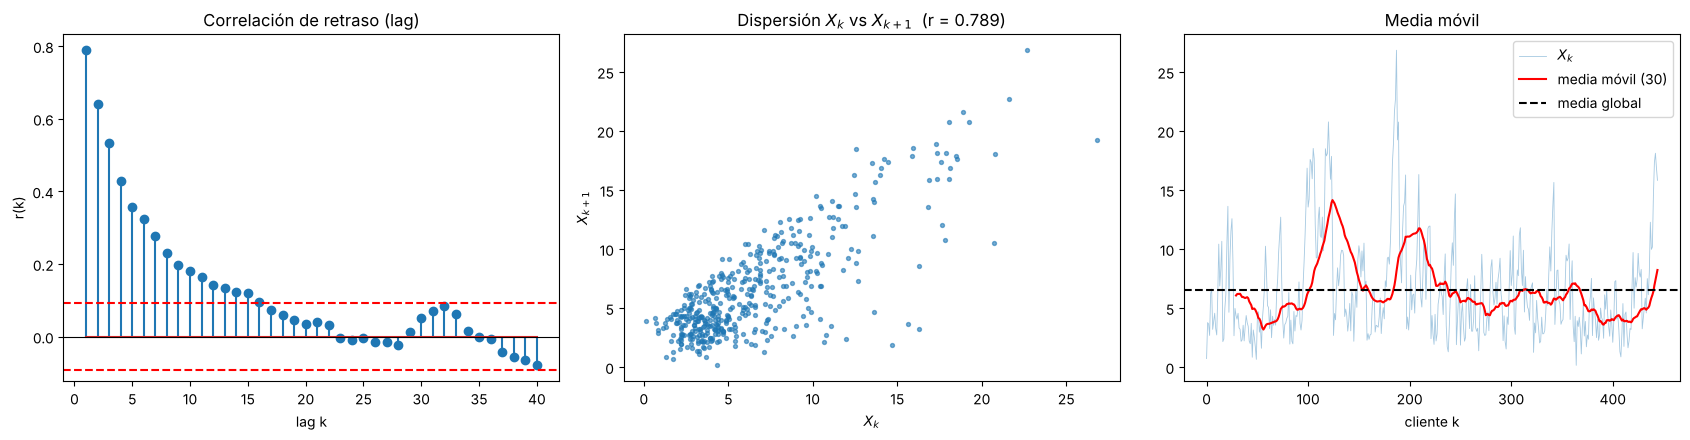

r(1) = 0.7888 | lags fuera de la banda ±0.093: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
Media 1ra mitad = 7.468, 2da mitad = 5.636


In [8]:
max_lag = 40
lags = np.arange(1, max_lag + 1)
xc = x - x.mean()
acf = np.array([np.sum(xc[:-k] * xc[k:]) / np.sum(xc**2) for k in lags])
banda = 1.96 / np.sqrt(len(x))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

ax[0].stem(lags, acf)
ax[0].axhline(banda, color='r', ls='--')
ax[0].axhline(-banda, color='r', ls='--')
ax[0].axhline(0, color='k', lw=0.8)
ax[0].set_title('Correlación de retraso (lag)')
ax[0].set_xlabel('lag k')
ax[0].set_ylabel('r(k)')

ax[1].scatter(x[:-1], x[1:], s=8, alpha=0.6)
ax[1].set_title(f'Dispersión $X_k$ vs $X_{{k+1}}$  (r = {acf[0]:.3f})')
ax[1].set_xlabel('$X_k$')
ax[1].set_ylabel('$X_{k+1}$')

ventana = 30
mm = pd.Series(x).rolling(ventana).mean()
ax[2].plot(x, lw=0.6, alpha=0.4, label='$X_k$')
ax[2].plot(mm, color='r', label=f'media móvil ({ventana})')
ax[2].axhline(x.mean(), color='k', ls='--', label='media global')
ax[2].set_title('Media móvil')
ax[2].set_xlabel('cliente k')
ax[2].legend()
plt.tight_layout()
plt.show()

mitad = len(x) // 2
print('r(1) =', round(acf[0], 4), '| lags fuera de la banda ±%.3f:' % banda, lags[np.abs(acf) > banda].tolist())
print('Media 1ra mitad = %.3f, 2da mitad = %.3f' % (x[:mitad].mean(), x[mitad:].mean()))

**Independencia:** no es independiente. La correlación entre un cliente y el siguiente es de 0.79, y hasta el retraso 16 las correlaciones siguen fuera de la banda ±1.96/√n. En el diagrama de dispersión los puntos suben juntos. Es lo normal en una cola: si un cliente esperó mucho, el que viene detrás encuentra la misma fila.

**Estacionariedad:** sí la considero estacionaria. La media móvil se dispara en dos momentos de congestión (entre los clientes 100 y 220), pero después regresa a la media global y no se ve una tendencia hacia arriba ni hacia abajo. Como ρ = 0.75 < 1, la cola no crece sin límite. Que la primera mitad tenga media 7.5 y la segunda 5.6 se debe a esas rachas, no a un cambio de nivel.

## E. Bondad de ajuste
Seis distribuciones ajustadas por máxima verosimilitud y comparadas con SSE, AIC y BIC.

In [9]:
xp = x[x > 0]
dens, bordes = np.histogram(xp, bins=20, density=True)
centros = (bordes[:-1] + bordes[1:]) / 2
cota = 1.01 * xp.max()

candidatas = {
    'Exponencial': (stats.expon,       dict(floc=0)),
    'Lognormal':   (stats.lognorm,     dict(floc=0)),
    'Gamma':       (stats.gamma,       dict(floc=0)),
    'Weibull':     (stats.weibull_min, dict(floc=0)),
    'Beta':        (stats.beta,        dict(floc=0, fscale=cota)),
    'Normal':      (stats.norm,        dict()),
}

filas, ajustes = [], {}
for nombre, (dist, fijos) in candidatas.items():
    par = dist.fit(xp, **fijos)
    k = len(par) - len(fijos)
    logL = np.sum(dist.logpdf(xp, *par))
    sse = np.sum((dens - dist.pdf(centros, *par))**2)
    ajustes[nombre] = (dist, par)
    nombres_par = (dist.shapes.split(', ') if dist.shapes else []) + ['loc', 'scale']
    filas.append({'Distribución': nombre,
                  'Parámetros': ', '.join(f'{p}={v:.4f}' for p, v in zip(nombres_par, par)),
                  'SSE': sse,
                  'AIC': 2*k - 2*logL,
                  'BIC': k*np.log(len(xp)) - 2*logL})

tabla_E = pd.DataFrame(filas).set_index('Distribución').sort_values('AIC')
print('n usado =', len(xp))
tabla_E

n usado = 445


,Parámetros,SSE,AIC,BIC
Distribución,,,,
Gamma,"a=2.6310, loc=0.0000, scale=2.4895",0.0027,2385.2427,2393.4388
Lognormal,"s=0.6580, loc=0.0000, scale=5.3523",0.0009,2387.2835,2395.4797
Weibull,"c=1.6455, loc=0.0000, scale=7.3703",0.0054,2412.2765,2420.4727
Beta,"a=1.7745, b=5.3252, loc=0.0000, scale=27.0982",0.0062,2443.5605,2451.7566
Normal,"loc=6.5499, scale=4.2880",0.0132,2562.5330,2570.7291
Exponencial,"loc=0.0000, scale=6.5499",0.0225,2564.7074,2568.8054


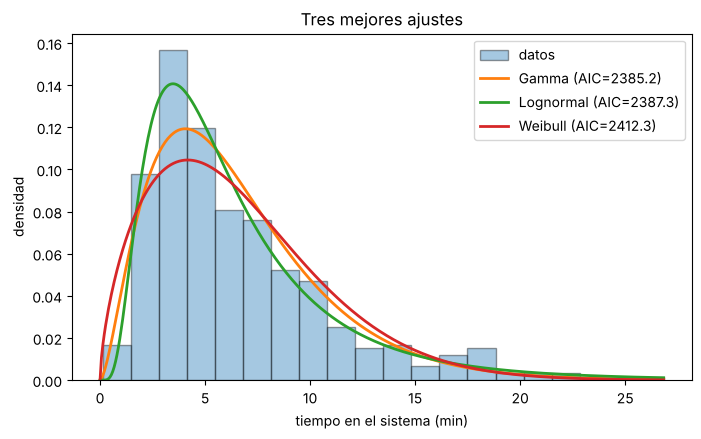

In [10]:
mejores = tabla_E.index[:3]
xs = np.linspace(0, xp.max(), 400)

plt.figure(figsize=(8, 4.5))
plt.hist(xp, bins=20, density=True, alpha=0.4, edgecolor='k', label='datos')
for nombre in mejores:
    dist, par = ajustes[nombre]
    plt.plot(xs, dist.pdf(xs, *par), lw=2, label=f'{nombre} (AIC={tabla_E.loc[nombre, "AIC"]:.1f})')
plt.xlabel('tiempo en el sistema (min)')
plt.ylabel('densidad')
plt.title('Tres mejores ajustes')
plt.legend()
plt.show()

**Justificación:** las tres que mejor ajustan son Gamma, Lognormal y Weibull. Entre Gamma y Lognormal la diferencia es mínima: la Gamma gana en AIC y BIC, y la Lognormal en SSE. La mejor seria Gamma (a = 2.63, scale = 2.49) porque tiene la mejor verosimilitud. La exponencial y la normal quedan muy atrás porque no capturan la asimetría de los datos.